# Forklift load volume - run top to bottom
Runs from the repo root. The video is not in the repo: `yt-dlp` downloads it if `video.mp4` is missing. Clicked points are in `outputs/points_*.json` (clicked by hand with `src/annotate.py`).
**D (3 EUR pallets) is most likely, not proven**: the number and type of pallets and the depth are unverified, see README. Mast clicks: `outputs/points_mast.json` (`src/annotate_mast.py`).

In [1]:
import os, subprocess, sys, json
os.chdir(os.path.abspath('..') if os.path.basename(os.getcwd())=='notebooks' else os.getcwd())
sys.path.insert(0, 'src')
env = dict(os.environ, PYTHONPATH='src', MPLBACKEND='Agg')
def run(*a): print(subprocess.run([sys.executable, *a], env=env, capture_output=True, text=True).stdout[-3000:])

## 1. Video and frames
Frames of the pass (21.7-22 s) are already in `frames/`. Re-download only if you want to rebuild them: `yt-dlp -f 'bv*[height<=1080]' -o video.mp4 https://www.youtube.com/watch?v=RCqa8Kojlw8`, then `python src/extract_frames.py`.

In [2]:
print(sorted(os.listdir('frames'))[:12])

['A_00999.jpg', 'A_01014.jpg', 'A_01050.jpg', 'A_01056.jpg', 'A_01062.jpg', 'A_01068.jpg', 'A_01086.jpg', 'A_01092.jpg', 'A_01098.jpg', 'A_01122.jpg', 'A_01128.jpg', 'A_01134.jpg']


## 2. Clicked points drawn on frame #1092

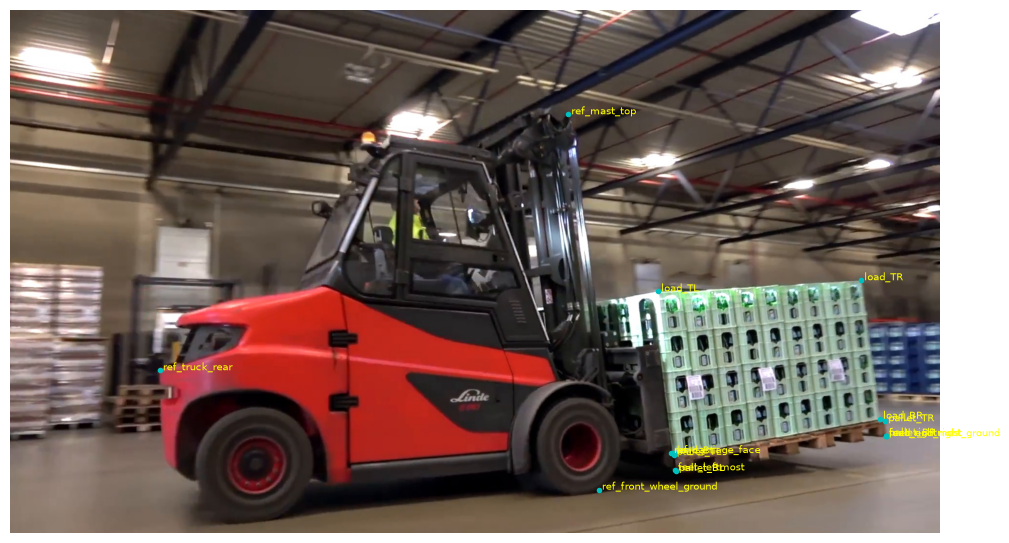

In [3]:
import cv2, numpy as np, matplotlib.pyplot as plt
from measure import load_points
P = load_points()['1092']
im = cv2.cvtColor(cv2.imread('frames/A_01092.jpg'), cv2.COLOR_BGR2RGB)
plt.figure(figsize=(12, 6.8)); plt.imshow(im)
for k, v in P.items(): plt.plot(*v, 'c.'); plt.text(v[0] + 6, v[1], k, color='yellow', fontsize=7)
plt.axis('off'); plt.show()

## 3a. Which mast? Mast/roof ratio and tyres (clicks in `outputs/points_mast.json`, tool `src/annotate_mast.py`)
The truck has the 3213 mm mast (h1/h6 = 1.132), not the 2888 mm one. All truck-scale numbers below use 3213 mm.

In [ ]:
run('src/mast_check.py')

## 3. Scales, heights and lengths per frame (plain arithmetic on the clicks)

In [4]:
run('src/measure.py')

ight height ratio of the load face 1.165;  case C pieces: {'pallet144/f800': (1.97, 0.56, 16), 'pallet144/f1400': (1.97, 0.99, 27), 'truck/f800': (1.72, 0.49, 16), 'truck/f1400': (1.72, 0.86, 27)} (Lx m, dZ m, turn deg)
homography, load face in mm: {'A one EUR pallet': (1112, 1314), 'B two pallets in a row': (2223, 1314)}
  V load only  A one EUR pallet         {0.8: '1.20-1.38', 1.2: '1.80-2.06'} m3
  V load only  B two pallets in a row   {0.8: '2.40-2.75', 1.2: '3.61-4.13'} m3
  V load only  C measured length        {0.8: '1.79-2.52', 1.2: '2.69-3.79'} m3
  V single-scale (naive) A {0.8: '0.82', 1.2: '1.23'} m3
  V single-scale (naive) B {0.8: '3.27', 1.2: '4.91'} m3

===== frame #1098 =====
px: {'pallet_len': 406.0, 'pallet_h_left': 30.9, 'pallet_h_right': 27.9, 'load_len': 390.0, 'load_h_left': 320.5, 'load_h_right': 273.4}
scales mm/px: {'pallet_height': 4.66, 'truck_vertical': 3.87, 'truck_horizontal': 4.05, 'pallet_length_A': 2.96, 'pallet_length_B': 5.91}
pallet long edge / pal

## 4. New frames #1062 / #1068 (right end cut off: left height and a length lower bound only)

In [5]:
run('src/new_frames.py')

1062 {'scale_mm_per_px': 3.208, 'H_left_m': 1.293, 'per_layer_mm': 323.205}
1068 {'scale_mm_per_px': 3.275, 'H_left_m': 1.282, 'per_layer_mm': 320.445, 'top_edge_px': 597.253, 'Lx_lower_bound_m': 1.956}
main frames (1086, 1092, 1098) left-end height m: [1.249, np.float64(1.252), 1.239]
all 5 frames: 1.24-1.29 m, mean 1.26 m (spread 4.3 %)



## 5. Monte Carlo (10,000 runs) per scenario A / B / C / D

In [6]:
run('src/uncertainty.py')

Median and ranges in m3, pooled over the 3 frames, width 0.8 m, truck scale

B-with-image-scale (2.4 m long but 4 layers of 290 mm: NOT self-consistent, kept only for comparison)
   load only        2.29  (80%: 2.09-2.50 | 95%: 2.02-2.58)
   load + pallets   2.56  (80%: 2.36-2.78 | 95%: 2.29-2.85)
   height 1.25 m | length 2.42 m | per-frame medians (#1086, #1092, #1098): [2.29, 2.3, 2.27]
A one EUR pallet (EXCLUDED by the clicks)
   load only        1.14  (80%: 1.04-1.24 | 95%: 1.00-1.28)
   load + pallets   1.27  (80%: 1.18-1.38 | 95%: 1.14-1.42)
   height 1.25 m | length 1.20 m | per-frame medians (#1086, #1092, #1098): [1.14, 1.14, 1.13]
C length from clicks + truck geometry
   load only        1.75  (80%: 1.47-2.06 | 95%: 1.39-2.17)
   load + pallets   1.96  (80%: 1.66-2.29 | 95%: 1.58-2.41)
   height 1.25 m | length 1.84 m | per-frame medians (#1086, #1092, #1098): [1.79, 1.76, 1.69]
SCENARIO B from crate count (L 2.4 m, H = 4 x 0.29-0.36 m, no image scale)
   load only        2.

## 5a. Pallet checks: EUR (144 mm) vs drinks pallet (166 mm), all length estimates, crate-shape check
#999 points are estimated by eye, not clicked.

In [ ]:
run('src/pallet_checks.py')

## 6. Results file and chart

{
 "note": "No single answer: scenario (number of pallets) is NOT verified. Volumes in m3, load only, 80 % range (p10-p90) INSIDE each scenario.",
 "scenarios_load_only_m3": {
  "B two pallets, height from image": {
   "median": 2.29,
   "p10": 2.09,
   "p90": 2.5
  },
  "A one EUR pallet (excluded)": {
   "median": 1.14,
   "p10": 1.04,
   "p90": 1.24
  },
  "C length from clicks": {
   "median": 1.75,
   "p10": 1.47,
   "p90": 2.06
  },
  "B two pallets, height from crates": {
   "median": 2.37,
   "p10": 2.15,
   "p90": 2.59
  },
  "D three pallets 2.4 x 1.2 m": {
   "median": 3.56,
   "p10": 3.38,
   "p90": 3.74
  }
 },
 "per_frame_height_m_truck_scale": {
  "1086": 1.249,
  "1092": 1.252,
  "1098": 1.239,
  "1062": 1.293,
  "1068": 1.282
 },
 "per_frame_height_m_pallet_scale": {
  "1086": 1.496,
  "1092": 1.434,
  "1098": 1.493
 },
 "length_lower_bound_m_frame_1068": 1.96,
 "monte_carlo_runs": 10000,
 "ranges_assumed": {
  "scale_bias": [
   -0.1,
   0.1
  ],
  "fill": [
   0.9,
 

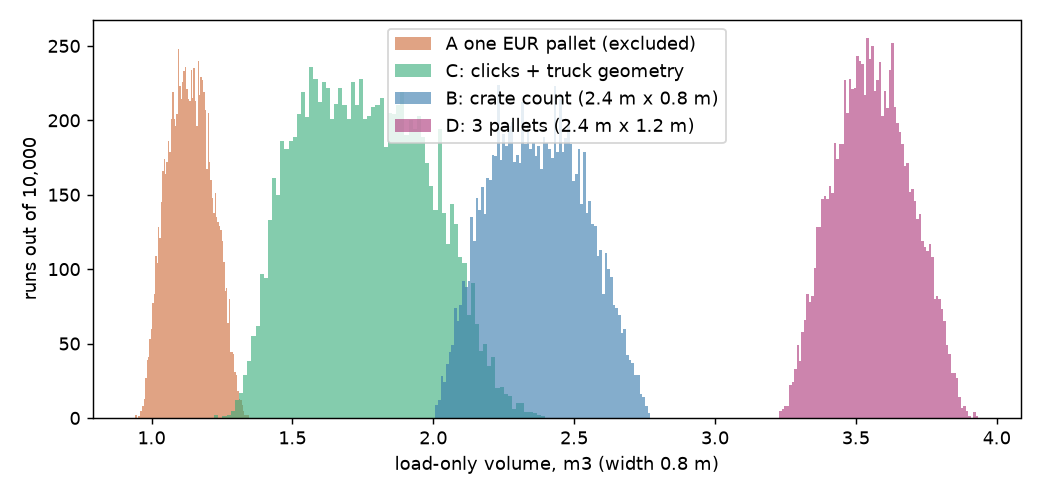

In [7]:
run('src/make_results.py')
from IPython.display import Image
Image('outputs/volume_hist.png')

## 7. Tests (fake box with known size + unit tests)

In [8]:
print(subprocess.run([sys.executable, '-m', 'pytest', 'tests', '-q'], capture_output=True, text=True).stdout[-600:])

...........                                                              [100%]
11 passed in 0.23s

